# Overview

# Analysis Preparation
## Loading Libraries and Data

In [523]:
from IPython.display import display
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

df = pd.read_csv("player_final_data.csv")

## Inspecting Original Data

In [524]:
df.head()

,NBA_ID,PLAYER_NAME,SEASON,POSITION,AGE,MIN_PER_GAME,GP_TOTAL,PTS_PER12,FGM_PER12,FGA_PER12,...,FG2_PCT,FG3_PCT,FT_PCT,EFG_PCT,THREE_POINT_ATTEMPT_SHARE,FREE_THROW_ATTEMPT_RATE,AST_TO_TOV,OREB_SHARE,DD2_PER_GAME,TD3_PER_GAME
0,2,Byron Scott,1996-97,G,36.0,18.062069,87.0,4.432990,1.382971,3.146239,...,0.501894,0.374004,0.845836,0.530704,0.487379,0.410922,1.799368,0.181609,0.000000,0.0
1,3,Grant Long,1996-97,F,31.0,17.964286,70.0,3.339960,1.254871,2.776938,...,0.459959,0.410526,0.774869,0.485395,0.163230,0.328179,0.923077,0.409483,0.028571,0.0
2,7,Dan Schayes,1996-97,C,38.0,12.630000,50.0,2.983373,1.026128,2.745843,...,0.373702,NaN,0.767241,0.373702,0.000000,0.401384,0.596774,0.322464,0.020000,0.0
3,9,Sedale Threatt,1996-97,G,35.0,16.216216,37.0,2.570000,0.994000,2.590000,...,0.405890,0.350195,0.774390,0.453282,0.396911,0.126641,3.460630,0.142506,0.000000,0.0
4,15,Eric Piatkowski,1996-97,G-F,26.0,11.544118,68.0,6.204841,2.146242,4.740382,...,0.459043,0.443079,0.847921,0.539987,0.393744,0.294744,1.142857,0.498586,0.000000,0.0


In [525]:
df.shape

(11242, 37)

In [526]:
summary = pd.concat(
    [df.dtypes, df.isna().sum(), df.iloc[0]],
    axis=1,
    keys=['Data Type', 'Missing Count', 'First Row Value']
)

# Note: .bfill takes the first

print(summary)

                          Data Type  Missing Count First Row Value
NBA_ID                        int64              0               2
PLAYER_NAME                  object              0     Byron Scott
SEASON                       object              0         1996-97
POSITION                     object              0               G
AGE                         float64              0            36.0
MIN_PER_GAME                float64              0       18.062069
GP_TOTAL                    float64              0            87.0
PTS_PER12                   float64              0         4.43299
FGM_PER12                   float64              0        1.382971
FGA_PER12                   float64              0        3.146239
FG2M_PER12                  float64              0        0.809469
FG2A_PER12                  float64              0        1.612829
FG3M_PER12                  float64              0        0.573501
FG3A_PER12                  float64              0         1.5

In [527]:
# Inspecting number of unique players
print(f"There are {len(df['PLAYER_NAME'].unique())} unique players in the data set.")

There are 2083 unique players in the data set.


In [528]:
# Need to make sure data is sorted by season since aggregating will work
# on the assumption the data is ordered by season when selecting position
# and age for players

df['SEASON'].unique()

array(['1996-97', '1997-98', '1998-99', '1999-00', '2000-01', '2001-02',
       '2002-03', '2003-04', '2004-05', '2005-06', '2006-07', '2007-08',
       '2008-09', '2009-10', '2010-11', '2011-12', '2012-13', '2013-14',
       '2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20',
       '2020-21', '2021-22', '2022-23'], dtype=object)

## Aggregating by Player and Inspecting

The features can be grouped as follows:  



| Points | Field Goals (2P and 3P) | 2P Shots | 3P Shots | Free-throws | Rebounds | Blocks | Personal Fouls | Assists and Turnovers | Steals | Other |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| PTS_PER12 | FGM_PER12 | FG2M_PER12 | FG3M_PER12 | FTM_PER12 | OREB_PER12 | BLK_PER12 | PF_PER12 | AST_PER12 | STL_PER12 | AGE |
| — | FGA_PER12 | FG2A_PER12 | FG3A_PER12 | FTA_PER12 | DREB_PER12 | BLKA_PER12 | PFD_PER12 | TOV_PER12 | — | MIN_PER_GAME |
| — | FG_PCT | FG2_PCT | FG3_PCT | FT_PCT | REB_PER12 | — | — | AST_TO_TOV | — | — |


Will need to recalculate percentage variables after aggregating to make sure that it is truly representative of career shooting per 12 minutes (instead of possibly giving each season an equal weight unfairly).

I will exclude the field goal variables because these contain less information than their separate counts between 2P and 3P shots. I will also exclude block attempts because it does not appear to be considered in other literature, total blocks is preferred.

In [529]:
# Intended features = ['AST_PER12','TOV_PER12','REB_PER12','BLK_PER12','STL_PER12', 'FG2A_PER12','FG3A_PER12','FTA_PER12']
# Aggregating by player
player_avg = df.groupby('PLAYER_NAME').agg({
    # Points
    'PTS_PER12': 'mean',
    # 2P Shots
    'FG2M_PER12': 'mean',
    'FG2A_PER12': 'mean',
    # 3P Shots
    'FG3M_PER12': 'mean',
    'FG3A_PER12': 'mean',
    # Free-throws
    'FTM_PER12': 'mean',
    'FTA_PER12': 'mean',
    # Rebounds
    'OREB_PER12': 'mean',
    'DREB_PER12': 'mean',
    'REB_PER12': 'mean',
    # Blocks
    'BLK_PER12': 'mean',
    # Personal Fouls
    'PF_PER12': 'mean',
    'PFD_PER12': 'mean',
    # Assists and Turnovers
    'AST_PER12': 'mean',
    'TOV_PER12': 'mean',
    'AST_TO_TOV': 'mean',
    # Steals
    'STL_PER12': 'mean',
    # Other
    'AGE': 'last', # Keeps the player's most recent age
    'MIN_PER_GAME': 'mean',
    # Position
    'POSITION': 'last'  # Keeps the last position entry found (can debate if we want
    # to instead group by player name and position since positions can change with each season)
}).reset_index()

# Recalculating percentages
player_avg['FG2_PCT'] = (
    player_avg['FG2M_PER12'] / player_avg['FG2A_PER12']
)
player_avg['FG3_PCT'] = (
    player_avg['FG3M_PER12'] / player_avg['FG3A_PER12']
)
player_avg['FT_PCT'] = (
    player_avg['FTM_PER12'] / player_avg['FTA_PER12']
)

#

In [530]:
player_avg.shape

(2083, 24)

In [531]:
summary = pd.concat(
    [player_avg.dtypes, player_avg.isna().sum(), player_avg.iloc[0]],
    axis=1,
    keys=['Data Type', 'Missing Count', 'First Row Value']
)

# Note: .bfill takes the first

print(summary)

             Data Type  Missing Count First Row Value
PLAYER_NAME     object              0      A.C. Green
PTS_PER12      float64              0        2.884566
FG2M_PER12     float64              0         1.19331
FG2A_PER12     float64              0        2.590025
FG3M_PER12     float64              0             0.0
FG3A_PER12     float64              0        0.055639
FTM_PER12      float64              0        0.523619
FTA_PER12      float64              0        0.787259
OREB_PER12     float64              0        1.015155
DREB_PER12     float64              0        1.936012
REB_PER12      float64              0         2.94836
BLK_PER12      float64              0         0.09697
PF_PER12       float64              0        0.840806
PFD_PER12      float64            498             NaN
AST_PER12      float64              0        0.409901
TOV_PER12      float64              0        0.312796
AST_TO_TOV     float64              1        1.336588
STL_PER12      float64      

### Inspecting Missings
#### 3-Point Percentage

In [532]:
# Visualizing values of the two variables for calculation (attempts and makes)
# when this variable is missing values
player_avg.loc[player_avg['FG3_PCT'].isna(), ['POSITION', 'MIN_PER_GAME', 'FG3M_PER12', 'FG3A_PER12']]

# Based on this it seems like a lot of the missing variables are created from
# zero division (dividing by 0)

,POSITION,MIN_PER_GAME,FG3M_PER12,FG3A_PER12
8,C,11.960214,0.0,0.0
21,C,17.329198,0.0,0.0
23,F,12.700000,0.0,0.0
32,F-C,15.100000,0.0,0.0
36,C,10.700000,0.0,0.0
...,...,...,...,...
2061,C,33.202262,0.0,0.0
2064,C-F,7.700000,0.0,0.0
2071,C,13.326410,0.0,0.0
2076,C,14.351012,0.0,0.0


In [533]:
print("Made 3-Points:")
print(player_avg.loc[player_avg['FG3_PCT'].isna(), 'FG3M_PER12'].describe())

print("\nAttempted 3-Points:")
print(player_avg.loc[player_avg['FG3_PCT'].isna(), 'FG3A_PER12'].describe())

# This confirms suscipions, all values for attempts when percentage is missing
# equals zero meaning zero division created missing values so they can be
# replaced with zero.

Made 3-Points:
count    226.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: FG3M_PER12, dtype: float64

Attempted 3-Points:
count    226.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: FG3A_PER12, dtype: float64


In [534]:
# Before imputing
print(f"Before imputation, there are {sum(player_avg['FG3_PCT'].isna())} missing values.")

# Imputing missing values with zero
player_avg['FG3_PCT'] = player_avg['FG3_PCT'].fillna(0)

# After imputing
print(f"After imputation, there are {sum(player_avg['FG3_PCT'].isna())} missing values.")

Before imputation, there are 226 missing values.
After imputation, there are 0 missing values.


#### Freethrow Percentage

In [535]:
# Visualizing values of the two variables for calculation (attempts and makes)
# when this variable is missing values
player_avg.loc[player_avg['FT_PCT'].isna(), ['POSITION', 'MIN_PER_GAME', 'FTM_PER12', 'FTA_PER12']]

,POSITION,MIN_PER_GAME,FTM_PER12,FTA_PER12
309,G,9.5,0.0,0.0
397,G,13.9,0.0,0.0
884,F,12.0,0.0,0.0
1056,G,14.0,0.0,0.0
1543,G,8.1,0.0,0.0


In [536]:
print("Made FT:")
print(player_avg.loc[player_avg['FT_PCT'].isna(), 'FTM_PER12'].describe())

print("\nAttempted FT:")
print(player_avg.loc[player_avg['FT_PCT'].isna(), 'FTA_PER12'].describe())

# This confirms suscipions, all values for attempts when percentage is missing
# equals zero meaning zero division created missing values so they can be
# replaced with zero.

Made FT:
count    5.0
mean     0.0
std      0.0
min      0.0
25%      0.0
50%      0.0
75%      0.0
max      0.0
Name: FTM_PER12, dtype: float64

Attempted FT:
count    5.0
mean     0.0
std      0.0
min      0.0
25%      0.0
50%      0.0
75%      0.0
max      0.0
Name: FTA_PER12, dtype: float64


In [537]:
# Before imputing
print(f"Before imputation, there are {sum(player_avg['FT_PCT'].isna())} missing values.")

# Imputing missing values with zero
player_avg['FT_PCT'] = player_avg['FT_PCT'].fillna(0)

# After imputing
print(f"After imputation, there are {sum(player_avg['FT_PCT'].isna())} missing values.")

Before imputation, there are 5 missing values.
After imputation, there are 0 missing values.


#### Personal Fouls Drawn

In [538]:
# Visualizing values of a relevant variable to drawing a foul, free throw attempts,
# because fouls can result in free throws
player_avg.loc[player_avg['PFD_PER12'].isna(), ['POSITION', 'MIN_PER_GAME', 'FTA_PER12']]

,POSITION,MIN_PER_GAME,FTA_PER12
0,F,24.038420,0.787259
1,G,16.200000,0.426551
16,F-C,10.600000,2.037736
18,F,14.617218,1.129421
23,F,12.700000,1.039370
...,...,...,...
2047,F,15.900000,2.113208
2056,F,13.900000,0.714107
2064,C-F,7.700000,1.402597
2071,C,13.326410,0.997179


In [539]:
player_avg['PFD_PER12'].describe() # This shows that people were having
# PFD equal to zero, so I will impute with the

,PFD_PER12
count,1585.000000
mean,0.880010
std,0.373576
min,0.000000
25%,0.617620
50%,0.822397
75%,1.085757
max,2.829681


In [540]:
print("Play time:")
print(player_avg.loc[player_avg['PFD_PER12'].isna(), 'MIN_PER_GAME'].describe())

print("\nAttempted FT:")
print(player_avg.loc[player_avg['PFD_PER12'].isna(), 'FTA_PER12'].describe())

print("\nMade FT (ALL DATA):")
print(player_avg['MIN_PER_GAME'].describe())

print("\nAttempted FT (ALL DATA):")
print(player_avg['FTA_PER12'].describe())

# After comparing the distributions on the two variables that could give insight
# into why fouls drawn is missing (very low play time or no free throw attempts)
# I do not see a real difference to justify imputing with zero like the other cases
# as such I will impute with the median.

Play time:
count    498.000000
mean      16.549224
std        7.455573
min        4.100000
25%       10.813942
50%       14.849961
75%       20.590817
max       38.564875
Name: MIN_PER_GAME, dtype: float64

Attempted FT:
count    498.000000
mean       1.046920
std        0.489338
min        0.000000
25%        0.702090
50%        0.977774
75%        1.294636
max        3.054545
Name: FTA_PER12, dtype: float64

Made FT (ALL DATA):
count    2083.000000
mean       18.217088
std         7.568124
min         4.100000
25%        12.400000
50%        17.130227
75%        23.571021
max        43.500000
Name: MIN_PER_GAME, dtype: float64

Attempted FT (ALL DATA):
count    2083.000000
mean        1.017913
std         0.482003
min         0.000000
25%         0.679774
50%         0.951492
75%         1.283001
max         3.671168
Name: FTA_PER12, dtype: float64


In [541]:
# Before imputing
print(f"Before imputation, there are {sum(player_avg['PFD_PER12'].isna())} missing values.")

# Imputing missing values with zero
player_avg['PFD_PER12'] = player_avg['PFD_PER12'].fillna(player_avg['PFD_PER12'].median())

# After imputing
print(f"After imputation, there are {sum(player_avg['PFD_PER12'].isna())} missing values.")


Before imputation, there are 498 missing values.
After imputation, there are 0 missing values.


### Inspecting Positions

In [542]:
frequencies = pd.concat(
    [player_avg['POSITION'].value_counts(), player_avg['POSITION'].value_counts(normalize=True)],
    axis=1,
    keys=['Count','Proportion']
)

print(frequencies)

          Count  Proportion
POSITION                   
G           762    0.365819
F           619    0.297168
C           247    0.118579
G-F         158    0.075852
F-C         122    0.058569
C-F         103    0.049448
F-G          72    0.034566


In [543]:
# Recoding G-F to F-G
player_avg['POSITION'] = player_avg['POSITION'].replace('G-F', 'F-G')

# Recoding C-F to F-C
player_avg['POSITION'] = player_avg['POSITION'].replace('C-F', 'F-C')

In [544]:
frequencies = pd.concat(
    [player_avg['POSITION'].value_counts(), player_avg['POSITION'].value_counts(normalize=True)],
    axis=1,
    keys=['Count','Proportion']
)

print(frequencies)

          Count  Proportion
POSITION                   
G           762    0.365819
F           619    0.297168
C           247    0.118579
F-G         230    0.110418
F-C         225    0.108017


## Considering Possible Features
[Towards Predicting Basketball Player Positions with Transformative Insights (Tsiannis & Efstathiades, 2025)](https://www.researchgate.net/publication/388725450_Towards_Predicting_Basketball_Player_Positions_with_Transformative_Insights)

The following article summaries the game statistics use in the relevant literature for player position classification models. Their results suggest that assists, total rebounds, blocks, steals, turnovers, personal fouls, and then types of shots attempted/made are valuable. Will plan to splits the shots attempted into features sets of the attempts and sets of the percentages to compare performance-wise. Similarly, minutes per game will be included to see if it changes model performace.

Describes that accuracy alongside a confusion matrix are the main metrics/methods of evaluating model performance. Some articles have included precision, recall, and F1 scores, but they are given less weight during evaluation.

In [545]:
# Defining target outcome
target = 'POSITION'

# First models will compare whether feature set 1 or 2 is better
# Feature set 1 (using attempts)
features_attempts = [
    'FG2A_PER12',
    'FG3A_PER12',
    'FTA_PER12',
    'REB_PER12',
    'BLK_PER12',
    'PF_PER12',
    'PFD_PER12',
    'AST_PER12',
    'TOV_PER12',
    'STL_PER12'
]

# Feature set 2 (using percentages)
features_percentages = [
    'FG2_PCT',
    'FG3_PCT',
    'FT_PCT',
    'REB_PER12',
    'BLK_PER12',
    'PF_PER12',
    'PFD_PER12',
    'AST_PER12',
    'TOV_PER12',
    'STL_PER12'
]

### Initial Correlation Matrices

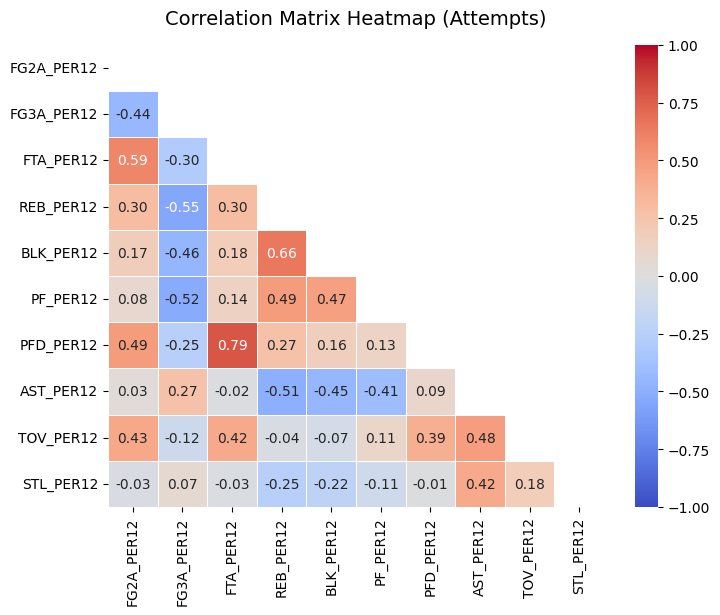

In [546]:
# 1. Attempts
corr_matrix = player_avg[features_attempts].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    mask=mask,  # Hides duplicate upper triangle info
    cmap="coolwarm",  # Red for positive, blue for negative correlation
    vmax=1.0,  # Max anchor for the colorbar
    vmin=-1.0,  # Min anchor for the colorbar
    annot=True,  # Shows the actual correlation numbers inside the cells
    fmt=".2f",  # Formats numbers to 2 decimal places
    linewidths=0.5,  # Adds a small gap between cells
)

plt.title("Correlation Matrix Heatmap (Attempts)", fontsize=14, pad=15)
plt.show()

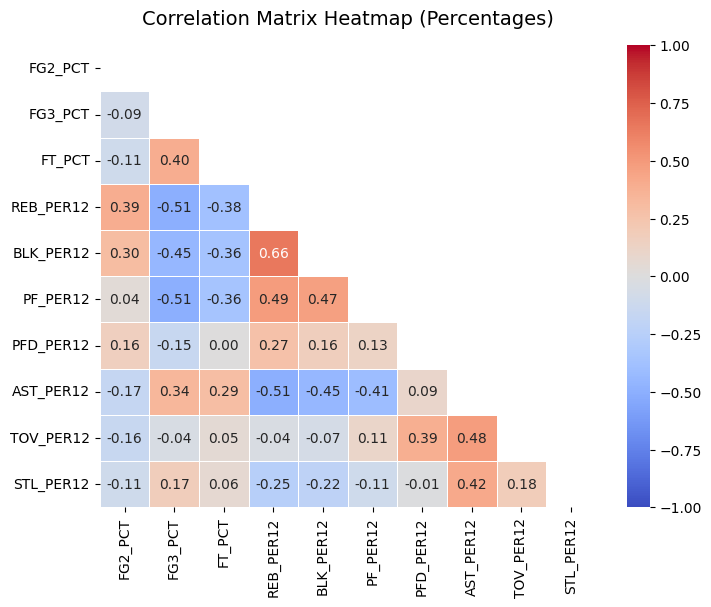

In [547]:
# 2. Percentages
corr_matrix = player_avg[features_percentages].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    mask=mask,  # Hides duplicate upper triangle info
    cmap="coolwarm",  # Red for positive, blue for negative correlation
    vmax=1.0,  # Max anchor for the colorbar
    vmin=-1.0,  # Min anchor for the colorbar
    annot=True,  # Shows the actual correlation numbers inside the cells
    fmt=".2f",  # Formats numbers to 2 decimal places
    linewidths=0.5,  # Adds a small gap between cells
)

plt.title("Correlation Matrix Heatmap (Percentages)", fontsize=14, pad=15)
plt.show()

### Altering Baseline Features

In [548]:
# An additional set of models will be used to decide whether additional
# features like minutes per game and age (or personal fouls drawn for %) are valuable.
# I am not including them in the original feature sets just because they are
# not seen as frequently for other people's models.

# Deciding to remove PFD from the baseline feature set due to
# concerns with multicollinearity for the the attempts features set
# which makes sense because if you are drawing more fouls you would
# be getting more attempts at the line.

# First models will compare whether feature set 1 or 2 is better
# Feature set 1 (using attempts)
features_attempts = [
    'FG2A_PER12',
    'FG3A_PER12',
    'FTA_PER12',
    'REB_PER12',
    'BLK_PER12',
    'PF_PER12',
    'AST_PER12',
    'TOV_PER12',
    'STL_PER12'
]

# Feature set 2 (using percentages)
features_percentages = [
    'FG2_PCT',
    'FG3_PCT',
    'FT_PCT',
    'REB_PER12',
    'BLK_PER12',
    'PF_PER12',
    'AST_PER12',
    'TOV_PER12',
    'STL_PER12'
]

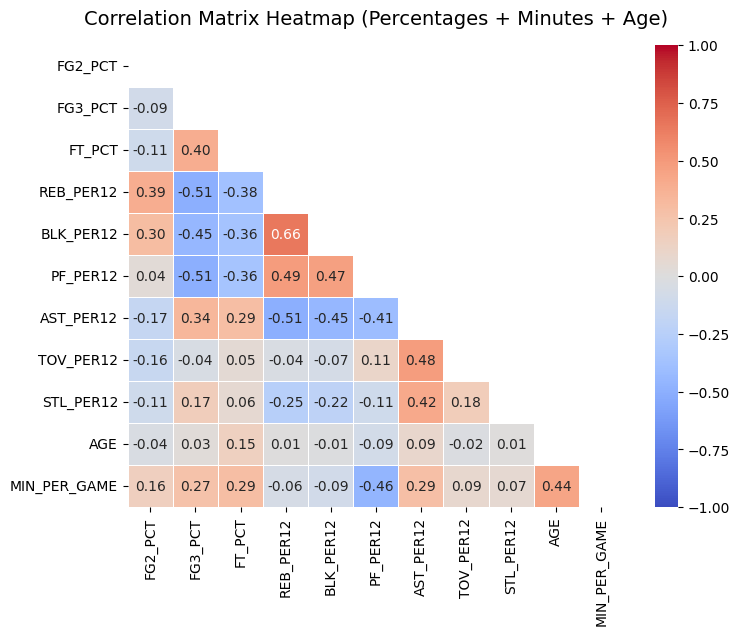

In [549]:
# Additional feature sets for attempts
features_minutes = features_percentages + ['MIN_PER_GAME']

features_age = features_percentages + ['AGE']

features_age_min = features_percentages + ['AGE', 'MIN_PER_GAME']

# Combined correlation matrix
corr_matrix = player_avg[features_age_min].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    mask=mask,  # Hides duplicate upper triangle info
    cmap="coolwarm",  # Red for positive, blue for negative correlation
    vmax=1.0,  # Max anchor for the colorbar
    vmin=-1.0,  # Min anchor for the colorbar
    annot=True,  # Shows the actual correlation numbers inside the cells
    fmt=".2f",  # Formats numbers to 2 decimal places
    linewidths=0.5,  # Adds a small gap between cells
)

plt.title("Correlation Matrix Heatmap (Percentages + Minutes + Age)", fontsize=14, pad=15)
plt.show()

In [550]:

# An additional set of models will be used to decide whether additional
# features like minutes per game age, fouls drawn (or all) are valuable. I am
# not including them in the original feature sets just because they are
# not seen as frequently for other people's models or because of the
# multicollinearity concern explained above.

features_minutes = features_percentages + ['MIN_PER_GAME']

features_age = features_percentages + ['AGE']

features_pfd = features_percentages + ['PFD_PER12']

features_all = features_percentages + ['MIN_PER_GAME', 'AGE', 'PFD_PER12']

# Attempts Models

## Correlation Matrix of All Possible Features

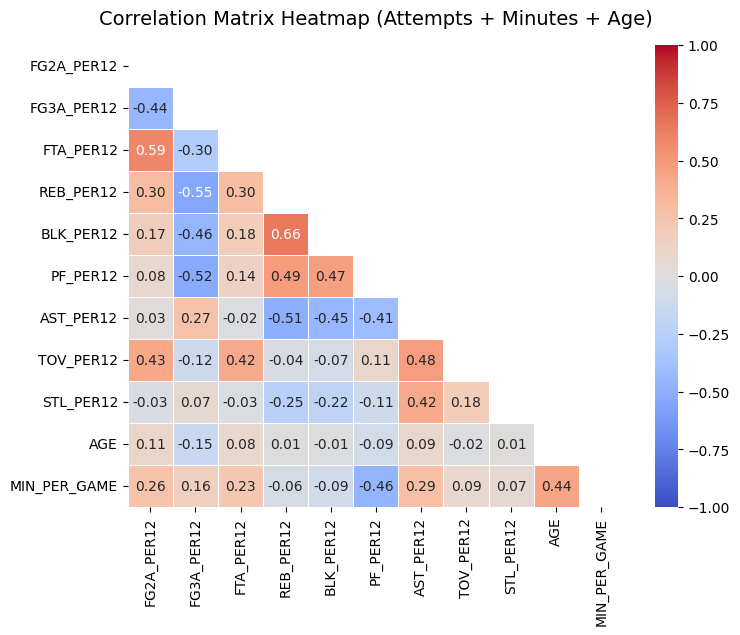

In [551]:
# Combined correlation matrix

# Additional feature sets for attempts
features_minutes = features_attempts + ['MIN_PER_GAME']

features_age = features_attempts + ['AGE']

features_all = features_attempts + ['AGE', 'MIN_PER_GAME']

# Combined correlation matrix
corr_matrix = player_avg[features_all].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    mask=mask,  # Hides duplicate upper triangle info
    cmap="coolwarm",  # Red for positive, blue for negative correlation
    vmax=1.0,  # Max anchor for the colorbar
    vmin=-1.0,  # Min anchor for the colorbar
    annot=True,  # Shows the actual correlation numbers inside the cells
    fmt=".2f",  # Formats numbers to 2 decimal places
    linewidths=0.5,  # Adds a small gap between cells
)

plt.title("Correlation Matrix Heatmap (Attempts + Minutes + Age)", fontsize=14, pad=15)
plt.show()

## (1) Baseline

In [552]:
# Defining KFold
kf = KFold(
    n_splits=10,
    shuffle=True,
    random_state=3001
)

In [553]:
X = player_avg[features_attempts]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_attempts
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2A_PER12', 'FG3A_PER12', 'FTA_PER12', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.656
Fold 2 - Accuracy: 0.675
Fold 3 - Accuracy: 0.636
Fold 4 - Accuracy: 0.702
Fold 5 - Accuracy: 0.673
Fold 6 - Accuracy: 0.673
Fold 7 - Accuracy: 0.625
Fold 8 - Accuracy: 0.644
Fold 9 - Accuracy: 0.596
Fold 10 - Accuracy: 0.668
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.579,0.660,0.612,24.700
F,0.576,0.750,0.650,61.900
F-C,0.463,0.179,0.251,22.500
F-G,0.467,0.036,0.065,23.000
G,0.777,0.910,0.837,76.200
accuracy,0.655,0.655,0.655,0.655
macro avg,0.572,0.507,0.483,208.300
weighted avg,0.631,0.655,0.606,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.566,0.664,0.596,26.500
F,0.599,0.762,0.659,62.500
F-C,0.444,0.155,0.214,22.000
F-G,0.500,0.039,0.073,23.000
G,0.775,0.912,0.836,77.000
accuracy,0.662,0.662,0.662,0.662
macro avg,0.565,0.505,0.477,208.000
weighted avg,0.641,0.662,0.615,208.000


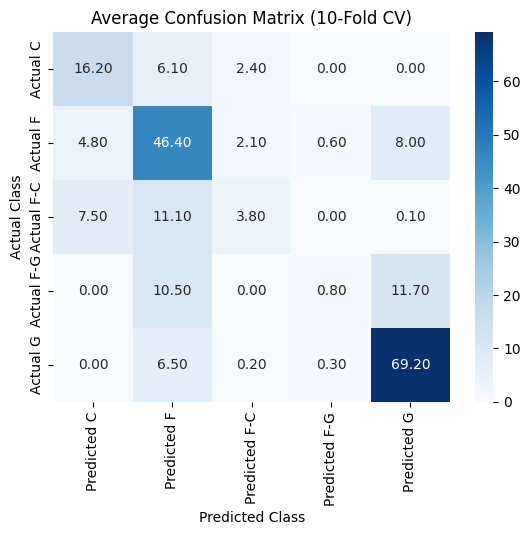

In [554]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_atmpt = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_atmpt.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

## (2) Handling Class Imbalance


In [555]:
X = player_avg[features_attempts]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_attempts
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2A_PER12', 'FG3A_PER12', 'FTA_PER12', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


### 2a. Class Weights

Fold 1 - Accuracy: 0.608
Fold 2 - Accuracy: 0.627
Fold 3 - Accuracy: 0.612
Fold 4 - Accuracy: 0.558
Fold 5 - Accuracy: 0.611
Fold 6 - Accuracy: 0.591
Fold 7 - Accuracy: 0.596
Fold 8 - Accuracy: 0.577
Fold 9 - Accuracy: 0.558
Fold 10 - Accuracy: 0.606
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.564,0.696,0.618,24.700
F,0.666,0.451,0.535,61.900
F-C,0.362,0.413,0.381,22.500
F-G,0.289,0.604,0.386,23.000
G,0.893,0.738,0.806,76.200
accuracy,0.594,0.594,0.594,0.594
macro avg,0.555,0.580,0.545,208.300
weighted avg,0.666,0.594,0.611,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.552,0.702,0.618,26.500
F,0.687,0.469,0.548,62.500
F-C,0.340,0.444,0.368,22.000
F-G,0.283,0.631,0.383,23.000
G,0.895,0.758,0.813,77.000
accuracy,0.601,0.601,0.601,0.601
macro avg,0.547,0.581,0.543,208.000
weighted avg,0.677,0.601,0.618,208.000


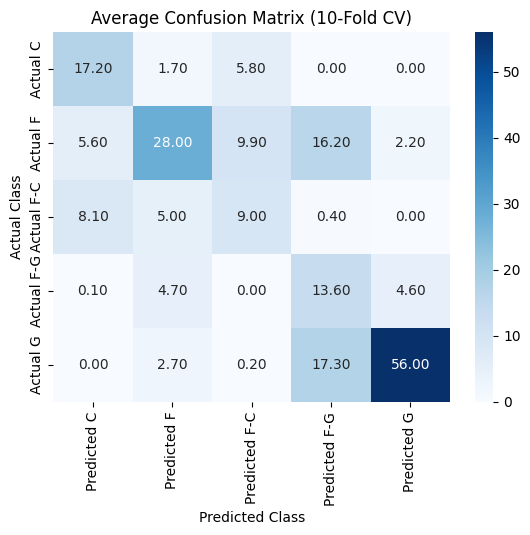

In [556]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression(class_weight='balanced')
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_weights = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_weights.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

### Comparison

Adding class weights ultimately worsens general accuracy, but it results in improved metrics for the minority classes for recall and f-1 score (not precision). For our project I think accuracy is most important, followed by the precision of classes which pushes me to not address the class imbalance.

In [557]:
print("Original: Median Classification Report:")
display(median_report_atmpt.round(3))

print("Class Weights: Median Classification Report:")
display(median_report_weights.round(3))

Original: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.566,0.664,0.596,26.500
F,0.599,0.762,0.659,62.500
F-C,0.444,0.155,0.214,22.000
F-G,0.500,0.039,0.073,23.000
G,0.775,0.912,0.836,77.000
accuracy,0.662,0.662,0.662,0.662
macro avg,0.565,0.505,0.477,208.000
weighted avg,0.641,0.662,0.615,208.000


Class Weights: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.552,0.702,0.618,26.500
F,0.687,0.469,0.548,62.500
F-C,0.340,0.444,0.368,22.000
F-G,0.283,0.631,0.383,23.000
G,0.895,0.758,0.813,77.000
accuracy,0.601,0.601,0.601,0.601
macro avg,0.547,0.581,0.543,208.000
weighted avg,0.677,0.601,0.618,208.000


## (3) Additional Features

### 3a. Age

In [558]:
X = player_avg[features_age]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_age
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2A_PER12', 'FG3A_PER12', 'FTA_PER12', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'AGE']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.665
Fold 2 - Accuracy: 0.67
Fold 3 - Accuracy: 0.665
Fold 4 - Accuracy: 0.697
Fold 5 - Accuracy: 0.663
Fold 6 - Accuracy: 0.659
Fold 7 - Accuracy: 0.606
Fold 8 - Accuracy: 0.654
Fold 9 - Accuracy: 0.606
Fold 10 - Accuracy: 0.702
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.578,0.647,0.605,24.700
F,0.581,0.763,0.658,61.900
F-C,0.502,0.234,0.310,22.500
F-G,0.243,0.028,0.049,23.000
G,0.780,0.901,0.836,76.200
accuracy,0.659,0.659,0.659,0.659
macro avg,0.537,0.515,0.491,208.300
weighted avg,0.613,0.659,0.612,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.562,0.641,0.593,26.500
F,0.556,0.771,0.653,62.500
F-C,0.453,0.229,0.287,22.000
F-G,0.000,0.000,0.000,23.000
G,0.791,0.899,0.834,77.000
accuracy,0.664,0.664,0.664,0.664
macro avg,0.515,0.507,0.494,208.000
weighted avg,0.611,0.664,0.618,208.000


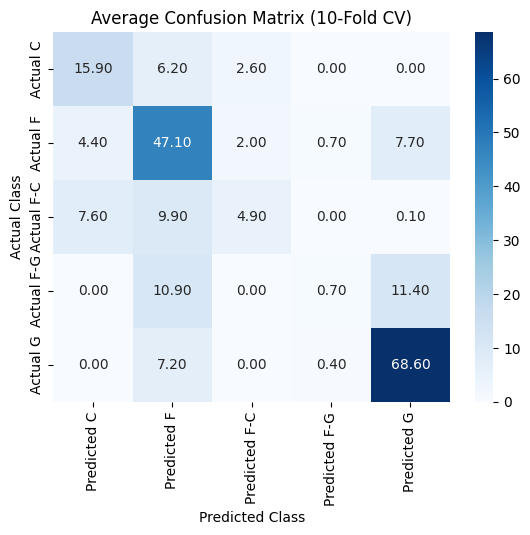

In [559]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_age = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_age.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

Age appears to improve accuracy overall and other metrics, particularly recall for minority classes.

### 3b. Minutes per game

In [560]:
X = player_avg[features_minutes]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_minutes
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2A_PER12', 'FG3A_PER12', 'FTA_PER12', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'MIN_PER_GAME']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.689
Fold 2 - Accuracy: 0.694
Fold 3 - Accuracy: 0.646
Fold 4 - Accuracy: 0.688
Fold 5 - Accuracy: 0.649
Fold 6 - Accuracy: 0.683
Fold 7 - Accuracy: 0.62
Fold 8 - Accuracy: 0.659
Fold 9 - Accuracy: 0.615
Fold 10 - Accuracy: 0.688
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.581,0.670,0.618,24.700
F,0.589,0.755,0.661,61.900
F-C,0.572,0.235,0.319,22.500
F-G,0.285,0.054,0.090,23.000
G,0.781,0.903,0.837,76.200
accuracy,0.663,0.663,0.663,0.663
macro avg,0.562,0.523,0.505,208.300
weighted avg,0.627,0.663,0.620,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.561,0.680,0.600,26.500
F,0.588,0.755,0.671,62.500
F-C,0.536,0.250,0.319,22.000
F-G,0.167,0.023,0.040,23.000
G,0.779,0.897,0.832,77.000
accuracy,0.671,0.671,0.671,0.671
macro avg,0.542,0.525,0.504,208.000
weighted avg,0.635,0.671,0.627,208.000


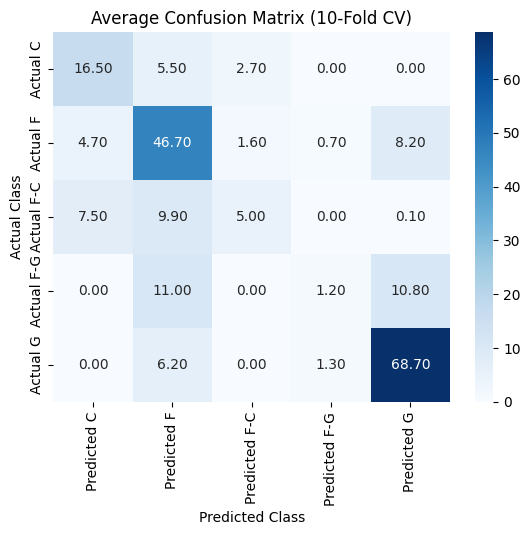

In [561]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_min = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_min.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

Including minutes per game appears to improve metrics all around.

### 3c. All potential features

In [562]:
X = player_avg[features_all]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_all
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2A_PER12', 'FG3A_PER12', 'FTA_PER12', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'AGE', 'MIN_PER_GAME']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.694
Fold 2 - Accuracy: 0.694
Fold 3 - Accuracy: 0.665
Fold 4 - Accuracy: 0.697
Fold 5 - Accuracy: 0.649
Fold 6 - Accuracy: 0.678
Fold 7 - Accuracy: 0.611
Fold 8 - Accuracy: 0.668
Fold 9 - Accuracy: 0.611
Fold 10 - Accuracy: 0.683
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.575,0.637,0.599,24.700
F,0.588,0.763,0.662,61.900
F-C,0.547,0.267,0.347,22.500
F-G,0.375,0.072,0.119,23.000
G,0.793,0.900,0.843,76.200
accuracy,0.665,0.665,0.665,0.665
macro avg,0.576,0.528,0.514,208.300
weighted avg,0.636,0.665,0.626,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.568,0.625,0.587,26.500
F,0.569,0.771,0.664,62.500
F-C,0.500,0.290,0.360,22.000
F-G,0.417,0.073,0.128,23.000
G,0.794,0.895,0.831,77.000
accuracy,0.673,0.673,0.673,0.673
macro avg,0.572,0.530,0.511,208.000
weighted avg,0.655,0.673,0.642,208.000


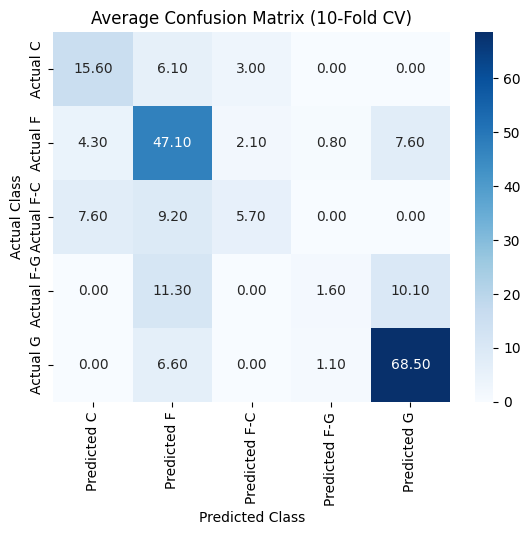

In [563]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_all = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_all.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

Really does not better than the age-only model.

### Comparison

In [564]:
print("Original: Median Classification Report:")
display(median_report_perc.round(3))

print("Age Addition: Median Classification Report:")
display(median_report_age.round(3))

print("Minutes Addition: Median Classification Report:")
display(median_report_min.round(3))

print("Fouls Drawn Addition: Median Classification Report:")
display(median_report_pfd.round(3))

print("All Additions: Median Classification Report:")
display(median_report_all.round(3))

Original: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.565,0.586,0.574,26.500
F,0.589,0.742,0.652,62.500
F-C,0.432,0.192,0.278,22.000
F-G,0.500,0.045,0.083,23.000
G,0.772,0.925,0.823,77.000
accuracy,0.655,0.655,0.655,0.655
macro avg,0.581,0.504,0.487,208.000
weighted avg,0.650,0.655,0.608,208.000


Age Addition: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.562,0.641,0.593,26.500
F,0.556,0.771,0.653,62.500
F-C,0.453,0.229,0.287,22.000
F-G,0.000,0.000,0.000,23.000
G,0.791,0.899,0.834,77.000
accuracy,0.664,0.664,0.664,0.664
macro avg,0.515,0.507,0.494,208.000
weighted avg,0.611,0.664,0.618,208.000


Minutes Addition: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.561,0.680,0.600,26.500
F,0.588,0.755,0.671,62.500
F-C,0.536,0.250,0.319,22.000
F-G,0.167,0.023,0.040,23.000
G,0.779,0.897,0.832,77.000
accuracy,0.671,0.671,0.671,0.671
macro avg,0.542,0.525,0.504,208.000
weighted avg,0.635,0.671,0.627,208.000


Fouls Drawn Addition: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.565,0.586,0.574,26.500
F,0.585,0.731,0.647,62.500
F-C,0.422,0.224,0.291,22.000
F-G,0.375,0.045,0.080,23.000
G,0.772,0.917,0.826,77.000
accuracy,0.659,0.659,0.659,0.659
macro avg,0.552,0.504,0.496,208.000
weighted avg,0.640,0.659,0.613,208.000


All Additions: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.568,0.625,0.587,26.500
F,0.569,0.771,0.664,62.500
F-C,0.500,0.290,0.360,22.000
F-G,0.417,0.073,0.128,23.000
G,0.794,0.895,0.831,77.000
accuracy,0.673,0.673,0.673,0.673
macro avg,0.572,0.530,0.511,208.000
weighted avg,0.655,0.673,0.642,208.000


#### Focusing on Age vs. All

In [565]:
print("Age Addition: Median Classification Report:")
display(median_report_age.round(3))

print("All Additions: Median Classification Report:")
display(median_report_all.round(3))

Age Addition: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.562,0.641,0.593,26.500
F,0.556,0.771,0.653,62.500
F-C,0.453,0.229,0.287,22.000
F-G,0.000,0.000,0.000,23.000
G,0.791,0.899,0.834,77.000
accuracy,0.664,0.664,0.664,0.664
macro avg,0.515,0.507,0.494,208.000
weighted avg,0.611,0.664,0.618,208.000


All Additions: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.568,0.625,0.587,26.500
F,0.569,0.771,0.664,62.500
F-C,0.500,0.290,0.360,22.000
F-G,0.417,0.073,0.128,23.000
G,0.794,0.895,0.831,77.000
accuracy,0.673,0.673,0.673,0.673
macro avg,0.572,0.530,0.511,208.000
weighted avg,0.655,0.673,0.642,208.000


If placing emphasis on accuracy and precision across classes, the best model is the one with the percentage features and the age variable added because it has the highest accuracy (67.6% vs. 67.4%) and it has a higher weighted average precision, which accounts for class imbalance (65.1% vs. 63.5%).

## Comparison of ALL Models

### Data Preparation

In [566]:
# Disclaimer: For this sectionI wanted a better way of visualizing the comparison so
# I applied basic programming concepts I know and referenced Python to
# R (a language I am more familiar with) resources to help me write the
# code below. I will include lots of comments to indicate comprehension
# of what I am doing since a lot of this was not covered in this specific
# class.

# Put all your classification reports in a dictionary that I can loop
reports = {
    "Attempts Baseline": median_report_atmpt.round(3),
    "Attempts Weights": median_report_weights.round(3),
    "Age Addition": median_report_age.round(3),
    "Minutes Addition": median_report_min.round(3),
    "All Additions": median_report_all.round(3)
}

# Metrics from the report tables I want to compare (also accuracy but I address
# this separately)
metrics = ["precision", "recall", "f1-score"]

# Initializing a data frame to save new results in for visualizing
data = []

# This loop is going to loop through each report (for a different model) to
# extract the report and its different metrics into nested lists that will be
# converted into rows for a data frame during visualization. I specifically want
# the metric name (class/type + metric; when applicable), the model name the report
# comes from, and the relevant score.
for model in reports:
    report = reports[model]

    for class_name in report.index:
      # Need to do special condition for accuracy since there is only one
      # accuracy score so I do not need it split across the metrics
      if class_name == "accuracy":
        data.append([
            "accuracy",
            model,
            report.loc[class_name, "f1-score"]
        ])
      else:
        # This handles everything else to create new names in rows indicating
        # the class or weighted/macro avg for each metric
        for metric in metrics:
            data.append([
                class_name + " - " + metric,
                model,
                report.loc[class_name, metric]
            ])

# This is where the nested rows from previous loop get converted into a
# a data frame for modeling
comparison = pd.DataFrame(
    data,
    columns=["Metric", "Model", "Score"]
)

# Now I want each model to be its own column for visualizing and grouping so
# I am pivoting the data
comparison = comparison.pivot(
    index="Metric",
    columns="Model",
    values="Score"
)

# Rearranging columns to follow initial ordering in dictionary
comparison = comparison[list(reports.keys())]

comparison.head()

Model,Attempts Baseline,Attempts Weights,Age Addition,Minutes Addition,All Additions
Metric,,,,,
C - f1-score,0.596,0.618,0.593,0.600,0.587
C - precision,0.566,0.552,0.562,0.561,0.568
C - recall,0.664,0.702,0.641,0.680,0.625
F - f1-score,0.659,0.548,0.653,0.671,0.664
F - precision,0.599,0.687,0.556,0.588,0.569


### All Metrics

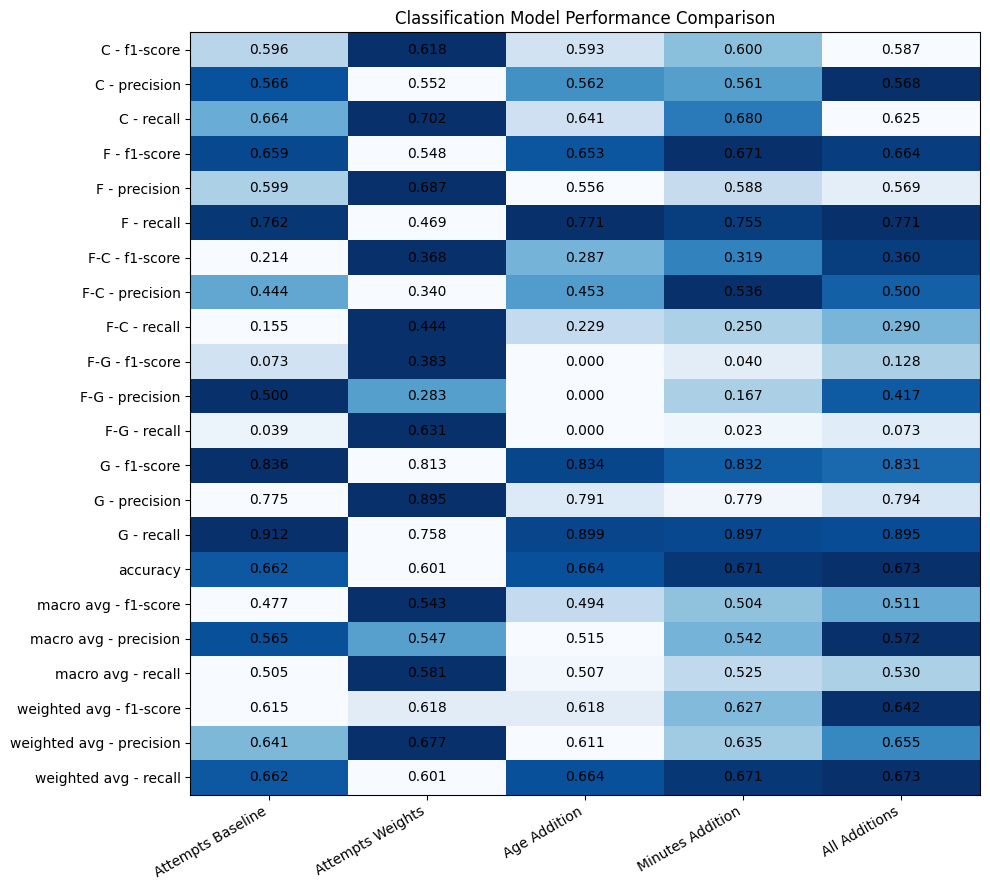

In [567]:
# Create heatmap
fig, ax = plt.subplots(figsize=(10, 9))

# Normalizing the scores within each row so that the coloring is
# distinguishable, need to do this because the differences in scores
# between models are relatively small so I don't want solid blue lines
normalized = comparison.sub(
    comparison.min(axis=1), axis=0
).div(
    comparison.max(axis=1) - comparison.min(axis=1), axis=0
)

# By applying the normalized scores in structuring of the heatmap I get
# the visual effect I want (will rewrite the shown values with actual ones
# though for interpretation purposes)
heatmap = ax.imshow(
    normalized,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto"
)

# Adding back original scores inside each cell
for row in range(len(comparison)):
    for col in range(len(comparison.columns)):
        value = comparison.iloc[row, col]

        ax.text(
            col, row,
            f"{value:.3f}",
            ha="center",
            va="center"
        )

# Labeling axes
ax.set_xticks(range(len(comparison.columns)))
ax.set_xticklabels(comparison.columns, rotation=30, ha="right")

ax.set_yticks(range(len(comparison.index)))
ax.set_yticklabels(comparison.index)

ax.set_title("Classification Model Performance Comparison")

plt.tight_layout()
plt.show()

### Metrics of Interest

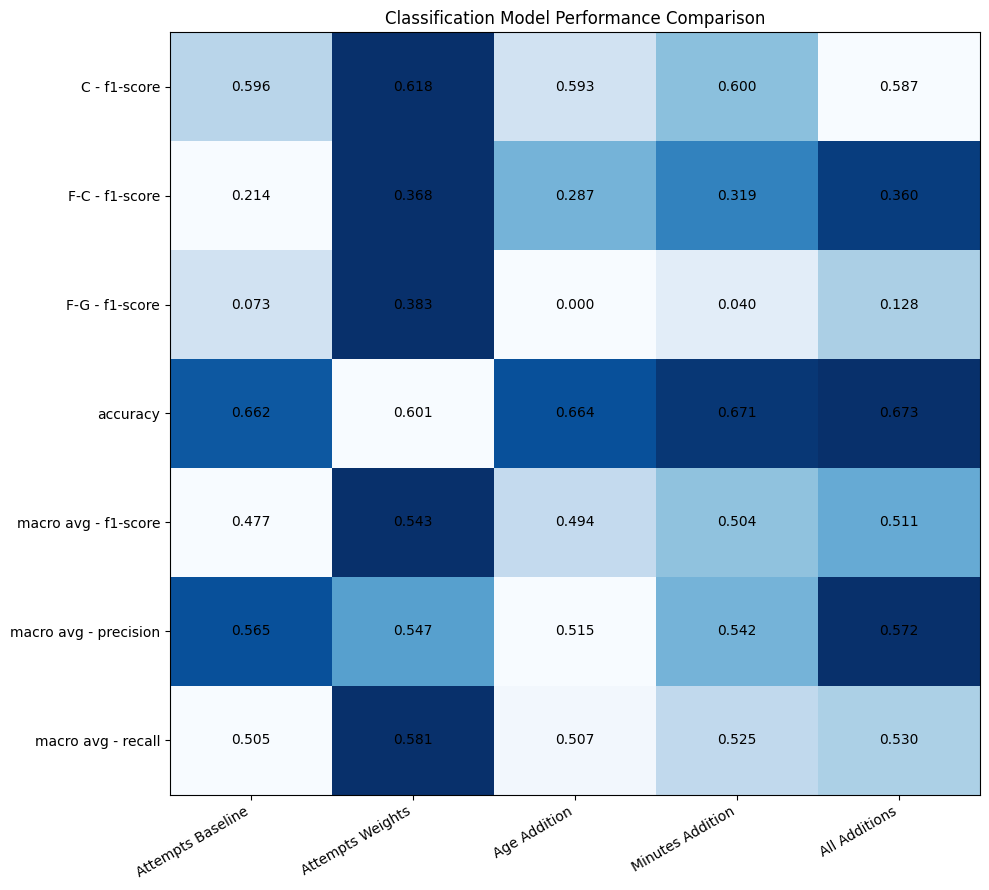

In [568]:
# Filtering to variables of particular interest
comparison_focused = comparison.iloc[[0,6,9,15,16,17,18]].copy()
comparison_focused.head()



# Create heatmap
fig, ax = plt.subplots(figsize=(10, 9))

# Normalizing the scores within each row so that the coloring is
# distinguishable, need to do this because the differences in scores
# between models are relatively small so I don't want solid blue lines
normalized = comparison_focused.sub(
    comparison_focused.min(axis=1), axis=0
).div(
    comparison_focused.max(axis=1) - comparison_focused.min(axis=1), axis=0
)

# By applying the normalized scores in structuring of the heatmap I get
# the visual effect I want (will rewrite the shown values with actual ones
# though for interpretation purposes)
heatmap = ax.imshow(
    normalized,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto"
)

# Adding back original scores inside each cell
for row in range(len(comparison_focused)):
    for col in range(len(comparison_focused.columns)):
        value = comparison_focused.iloc[row, col]

        ax.text(
            col, row,
            f"{value:.3f}",
            ha="center",
            va="center"
        )

# Labeling axes
ax.set_xticks(range(len(comparison_focused.columns)))
ax.set_xticklabels(comparison_focused.columns, rotation=30, ha="right")

ax.set_yticks(range(len(comparison_focused.index)))
ax.set_yticklabels(comparison_focused.index)

ax.set_title("Classification Model Performance Comparison")

plt.tight_layout()
plt.show()

Since accuracy is our most important metric, the best model using attempts is the one including all additional indicators followed by the minutes addition.

# Percentages Models

## Correlation Matrix of All Possible Features

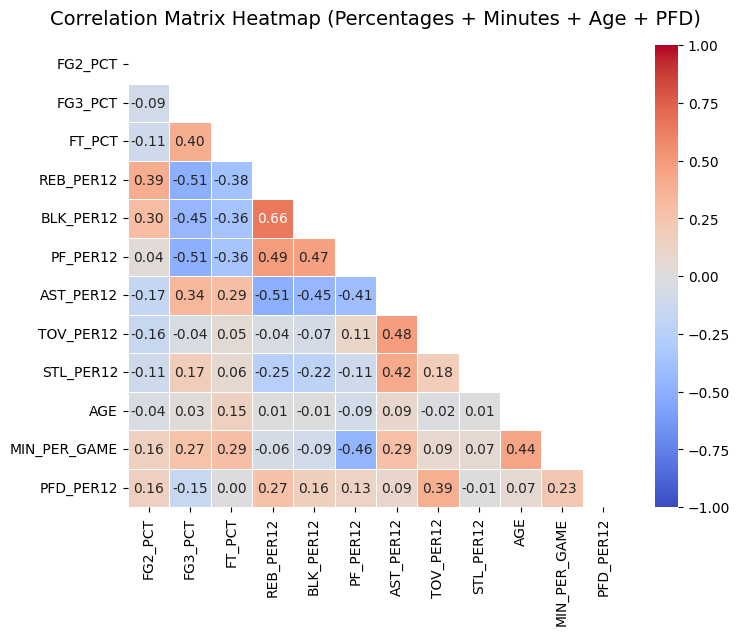

In [569]:
# Combined correlation matrix

# Additional feature sets for attempts
features_minutes = features_percentages + ['MIN_PER_GAME']

features_age = features_percentages + ['AGE']

features_pfd = features_percentages + ['PFD_PER12']

features_all = features_percentages + ['AGE', 'MIN_PER_GAME', 'PFD_PER12']

# Combined correlation matrix
corr_matrix = player_avg[features_all].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    mask=mask,  # Hides duplicate upper triangle info
    cmap="coolwarm",  # Red for positive, blue for negative correlation
    vmax=1.0,  # Max anchor for the colorbar
    vmin=-1.0,  # Min anchor for the colorbar
    annot=True,  # Shows the actual correlation numbers inside the cells
    fmt=".2f",  # Formats numbers to 2 decimal places
    linewidths=0.5,  # Adds a small gap between cells
)

plt.title("Correlation Matrix Heatmap (Percentages + Minutes + Age + PFD)", fontsize=14, pad=15)
plt.show()

## (1) Baseline

In [570]:
# Defining KFold
kf = KFold(
    n_splits=10,
    shuffle=True,
    random_state=3001
)

In [571]:
X = player_avg[features_percentages]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_percentages
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2_PCT', 'FG3_PCT', 'FT_PCT', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.651
Fold 2 - Accuracy: 0.689
Fold 3 - Accuracy: 0.636
Fold 4 - Accuracy: 0.688
Fold 5 - Accuracy: 0.659
Fold 6 - Accuracy: 0.668
Fold 7 - Accuracy: 0.625
Fold 8 - Accuracy: 0.635
Fold 9 - Accuracy: 0.587
Fold 10 - Accuracy: 0.678
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.571,0.601,0.583,24.700
F,0.575,0.753,0.650,61.900
F-C,0.458,0.215,0.288,22.500
F-G,0.533,0.038,0.069,23.000
G,0.771,0.903,0.830,76.200
accuracy,0.651,0.651,0.651,0.651
macro avg,0.582,0.502,0.484,208.300
weighted avg,0.631,0.651,0.605,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.565,0.586,0.574,26.500
F,0.589,0.742,0.652,62.500
F-C,0.432,0.192,0.278,22.000
F-G,0.500,0.045,0.083,23.000
G,0.772,0.925,0.823,77.000
accuracy,0.655,0.655,0.655,0.655
macro avg,0.581,0.504,0.487,208.000
weighted avg,0.650,0.655,0.608,208.000


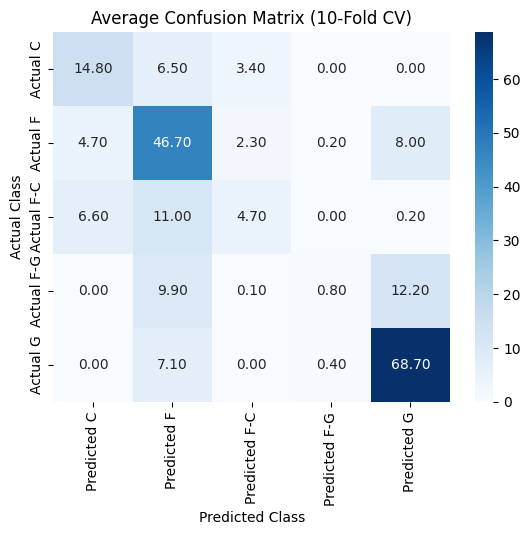

In [572]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_perc = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_perc.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [573]:
print("Attempts: Median Classification Report:")
display(median_report_atmpt.round(3))

print("Percentages: Median Classification Report:")
display(median_report_perc.round(3))

Attempts: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.566,0.664,0.596,26.500
F,0.599,0.762,0.659,62.500
F-C,0.444,0.155,0.214,22.000
F-G,0.500,0.039,0.073,23.000
G,0.775,0.912,0.836,77.000
accuracy,0.662,0.662,0.662,0.662
macro avg,0.565,0.505,0.477,208.000
weighted avg,0.641,0.662,0.615,208.000


Percentages: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.565,0.586,0.574,26.500
F,0.589,0.742,0.652,62.500
F-C,0.432,0.192,0.278,22.000
F-G,0.500,0.045,0.083,23.000
G,0.772,0.925,0.823,77.000
accuracy,0.655,0.655,0.655,0.655
macro avg,0.581,0.504,0.487,208.000
weighted avg,0.650,0.655,0.608,208.000


## (2) Handling Class Imbalance


In [574]:
X = player_avg[features_percentages]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_percentages
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2_PCT', 'FG3_PCT', 'FT_PCT', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


### 2a. Class Weights

Fold 1 - Accuracy: 0.589
Fold 2 - Accuracy: 0.632
Fold 3 - Accuracy: 0.617
Fold 4 - Accuracy: 0.601
Fold 5 - Accuracy: 0.601
Fold 6 - Accuracy: 0.562
Fold 7 - Accuracy: 0.611
Fold 8 - Accuracy: 0.587
Fold 9 - Accuracy: 0.548
Fold 10 - Accuracy: 0.591
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.561,0.637,0.593,24.700
F,0.676,0.465,0.550,61.900
F-C,0.386,0.475,0.423,22.500
F-G,0.282,0.600,0.379,23.000
G,0.888,0.726,0.797,76.200
accuracy,0.594,0.594,0.594,0.594
macro avg,0.559,0.581,0.548,208.300
weighted avg,0.669,0.594,0.614,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.542,0.631,0.581,26.500
F,0.671,0.479,0.552,62.500
F-C,0.375,0.458,0.405,22.000
F-G,0.271,0.583,0.373,23.000
G,0.884,0.736,0.800,77.000
accuracy,0.596,0.596,0.596,0.596
macro avg,0.557,0.579,0.555,208.000
weighted avg,0.671,0.596,0.614,208.000


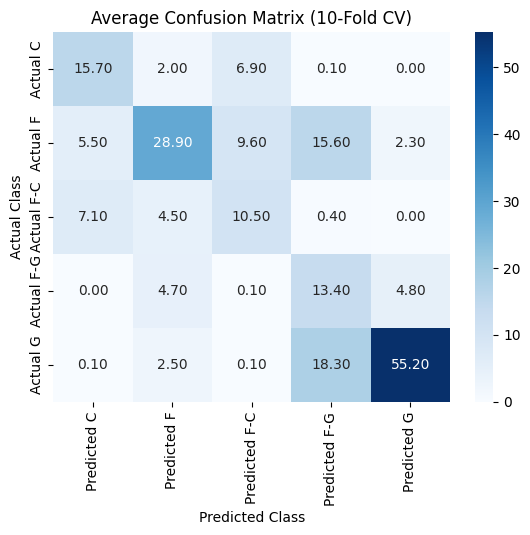

In [575]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression(class_weight='balanced')
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_weights = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_weights.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

### Comparison

Adding class weights ultimately worsens general accuracy, but it results in improved metrics for the minority classes for recall and f-1 score (not precision). For our project I think accuracy is most important, followed by the precision of classes which pushes me to not address the class imbalance.

In [576]:
print("Original: Median Classification Report:")
display(median_report_perc.round(3))

print("Class Weights: Median Classification Report:")
display(median_report_weights.round(3))

Original: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.565,0.586,0.574,26.500
F,0.589,0.742,0.652,62.500
F-C,0.432,0.192,0.278,22.000
F-G,0.500,0.045,0.083,23.000
G,0.772,0.925,0.823,77.000
accuracy,0.655,0.655,0.655,0.655
macro avg,0.581,0.504,0.487,208.000
weighted avg,0.650,0.655,0.608,208.000


Class Weights: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.542,0.631,0.581,26.500
F,0.671,0.479,0.552,62.500
F-C,0.375,0.458,0.405,22.000
F-G,0.271,0.583,0.373,23.000
G,0.884,0.736,0.800,77.000
accuracy,0.596,0.596,0.596,0.596
macro avg,0.557,0.579,0.555,208.000
weighted avg,0.671,0.596,0.614,208.000


## (3) Additional Features

### 3a. Age

In [577]:
X = player_avg[features_age]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_age
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2_PCT', 'FG3_PCT', 'FT_PCT', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'AGE']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.679
Fold 2 - Accuracy: 0.679
Fold 3 - Accuracy: 0.651
Fold 4 - Accuracy: 0.692
Fold 5 - Accuracy: 0.663
Fold 6 - Accuracy: 0.673
Fold 7 - Accuracy: 0.625
Fold 8 - Accuracy: 0.688
Fold 9 - Accuracy: 0.606
Fold 10 - Accuracy: 0.692
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.583,0.592,0.585,24.700
F,0.602,0.770,0.674,61.900
F-C,0.467,0.281,0.346,22.500
F-G,0.385,0.059,0.099,23.000
G,0.785,0.906,0.841,76.200
accuracy,0.665,0.665,0.665,0.665
macro avg,0.564,0.522,0.509,208.300
weighted avg,0.630,0.665,0.625,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.561,0.568,0.564,26.500
F,0.582,0.774,0.664,62.500
F-C,0.427,0.257,0.319,22.000
F-G,0.367,0.047,0.082,23.000
G,0.781,0.904,0.830,77.000
accuracy,0.676,0.676,0.676,0.676
macro avg,0.560,0.518,0.514,208.000
weighted avg,0.651,0.676,0.641,208.000


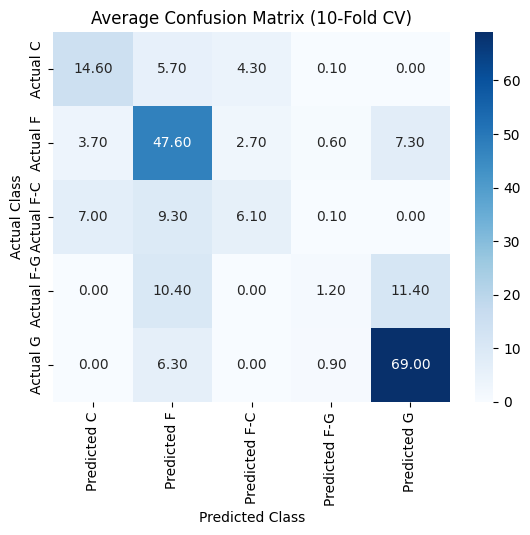

In [578]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_age = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_age.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

Age appears to improve accuracy overall and other metrics, particularly recall for minority classes.

### 3b. Minutes per game

In [579]:
X = player_avg[features_minutes]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_minutes
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2_PCT', 'FG3_PCT', 'FT_PCT', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'MIN_PER_GAME']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.675
Fold 2 - Accuracy: 0.699
Fold 3 - Accuracy: 0.632
Fold 4 - Accuracy: 0.692
Fold 5 - Accuracy: 0.644
Fold 6 - Accuracy: 0.683
Fold 7 - Accuracy: 0.615
Fold 8 - Accuracy: 0.663
Fold 9 - Accuracy: 0.601
Fold 10 - Accuracy: 0.663
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.582,0.610,0.594,24.700
F,0.588,0.749,0.657,61.900
F-C,0.474,0.255,0.324,22.500
F-G,0.393,0.066,0.111,23.000
G,0.775,0.900,0.833,76.200
accuracy,0.657,0.657,0.657,0.657
macro avg,0.562,0.516,0.504,208.300
weighted avg,0.626,0.657,0.618,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.577,0.595,0.578,26.500
F,0.592,0.743,0.657,62.500
F-C,0.441,0.230,0.306,22.000
F-G,0.500,0.080,0.133,23.000
G,0.782,0.895,0.829,77.000
accuracy,0.663,0.663,0.663,0.663
macro avg,0.565,0.515,0.505,208.000
weighted avg,0.620,0.663,0.636,208.000


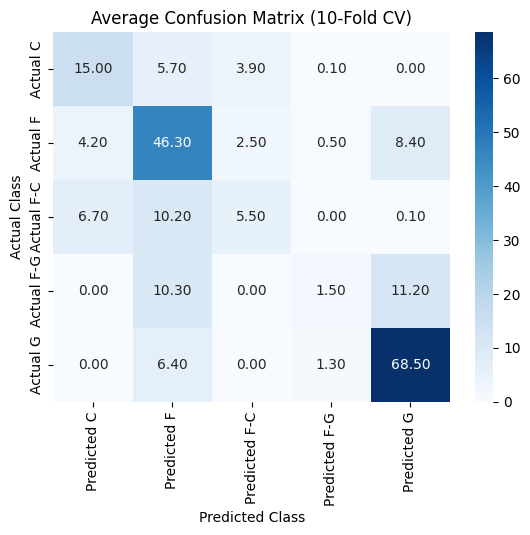

In [580]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_min = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_min.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

Including minutes per game appears to improve metrics all around.

### 3c. Fouls drawn

In [581]:
X = player_avg[features_pfd]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_pfd
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2_PCT', 'FG3_PCT', 'FT_PCT', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'PFD_PER12']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.656
Fold 2 - Accuracy: 0.689
Fold 3 - Accuracy: 0.636
Fold 4 - Accuracy: 0.678
Fold 5 - Accuracy: 0.668
Fold 6 - Accuracy: 0.663
Fold 7 - Accuracy: 0.625
Fold 8 - Accuracy: 0.63
Fold 9 - Accuracy: 0.577
Fold 10 - Accuracy: 0.683
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.585,0.601,0.590,24.70
F,0.572,0.744,0.645,61.90
F-C,0.447,0.228,0.297,22.50
F-G,0.425,0.040,0.071,23.00
G,0.773,0.904,0.832,76.20
accuracy,0.650,0.650,0.650,0.65
macro avg,0.560,0.503,0.487,208.30
weighted avg,0.617,0.650,0.606,208.30


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.565,0.586,0.574,26.500
F,0.585,0.731,0.647,62.500
F-C,0.422,0.224,0.291,22.000
F-G,0.375,0.045,0.080,23.000
G,0.772,0.917,0.826,77.000
accuracy,0.659,0.659,0.659,0.659
macro avg,0.552,0.504,0.496,208.000
weighted avg,0.640,0.659,0.613,208.000


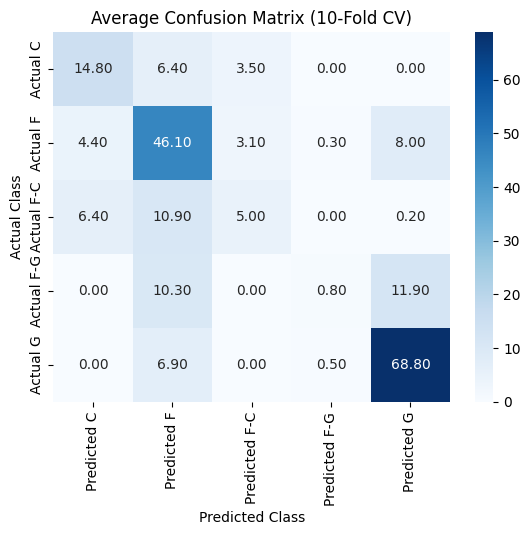

In [582]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_pfd = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_pfd.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

PFD also shows improvement.

### 3d. All potential features

In [583]:
X = player_avg[features_all]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_all
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2_PCT', 'FG3_PCT', 'FT_PCT', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'AGE', 'MIN_PER_GAME', 'PFD_PER12']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.675
Fold 2 - Accuracy: 0.684
Fold 3 - Accuracy: 0.641
Fold 4 - Accuracy: 0.712
Fold 5 - Accuracy: 0.644
Fold 6 - Accuracy: 0.683
Fold 7 - Accuracy: 0.62
Fold 8 - Accuracy: 0.683
Fold 9 - Accuracy: 0.615
Fold 10 - Accuracy: 0.673
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.587,0.592,0.586,24.700
F,0.591,0.763,0.664,61.900
F-C,0.472,0.282,0.347,22.500
F-G,0.389,0.072,0.120,23.000
G,0.792,0.903,0.843,76.200
accuracy,0.663,0.663,0.663,0.663
macro avg,0.566,0.522,0.512,208.300
weighted avg,0.632,0.663,0.626,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.564,0.568,0.566,26.500
F,0.575,0.771,0.659,62.500
F-C,0.444,0.268,0.333,22.000
F-G,0.350,0.077,0.129,23.000
G,0.792,0.895,0.840,77.000
accuracy,0.674,0.674,0.674,0.674
macro avg,0.562,0.518,0.505,208.000
weighted avg,0.635,0.674,0.641,208.000


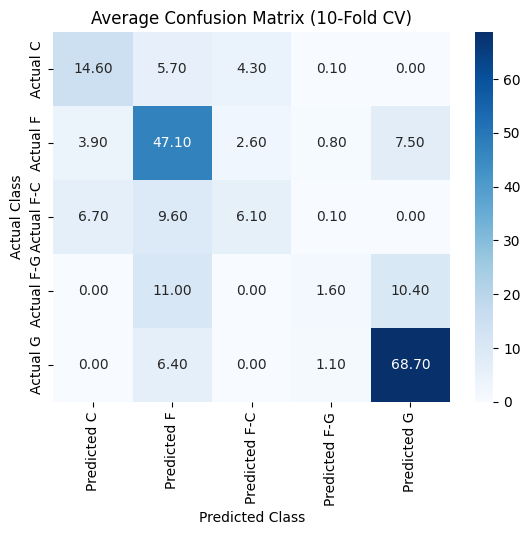

In [584]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_all = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_all.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

Really does not better than the age-only model.

### Comparison

In [585]:
print("Original: Median Classification Report:")
display(median_report_perc.round(3))

print("Age Addition: Median Classification Report:")
display(median_report_age.round(3))

print("Minutes Addition: Median Classification Report:")
display(median_report_min.round(3))

print("Fouls Drawn Addition: Median Classification Report:")
display(median_report_pfd.round(3))

print("All Additions: Median Classification Report:")
display(median_report_all.round(3))

Original: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.565,0.586,0.574,26.500
F,0.589,0.742,0.652,62.500
F-C,0.432,0.192,0.278,22.000
F-G,0.500,0.045,0.083,23.000
G,0.772,0.925,0.823,77.000
accuracy,0.655,0.655,0.655,0.655
macro avg,0.581,0.504,0.487,208.000
weighted avg,0.650,0.655,0.608,208.000


Age Addition: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.561,0.568,0.564,26.500
F,0.582,0.774,0.664,62.500
F-C,0.427,0.257,0.319,22.000
F-G,0.367,0.047,0.082,23.000
G,0.781,0.904,0.830,77.000
accuracy,0.676,0.676,0.676,0.676
macro avg,0.560,0.518,0.514,208.000
weighted avg,0.651,0.676,0.641,208.000


Minutes Addition: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.577,0.595,0.578,26.500
F,0.592,0.743,0.657,62.500
F-C,0.441,0.230,0.306,22.000
F-G,0.500,0.080,0.133,23.000
G,0.782,0.895,0.829,77.000
accuracy,0.663,0.663,0.663,0.663
macro avg,0.565,0.515,0.505,208.000
weighted avg,0.620,0.663,0.636,208.000


Fouls Drawn Addition: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.565,0.586,0.574,26.500
F,0.585,0.731,0.647,62.500
F-C,0.422,0.224,0.291,22.000
F-G,0.375,0.045,0.080,23.000
G,0.772,0.917,0.826,77.000
accuracy,0.659,0.659,0.659,0.659
macro avg,0.552,0.504,0.496,208.000
weighted avg,0.640,0.659,0.613,208.000


All Additions: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.564,0.568,0.566,26.500
F,0.575,0.771,0.659,62.500
F-C,0.444,0.268,0.333,22.000
F-G,0.350,0.077,0.129,23.000
G,0.792,0.895,0.840,77.000
accuracy,0.674,0.674,0.674,0.674
macro avg,0.562,0.518,0.505,208.000
weighted avg,0.635,0.674,0.641,208.000


#### Focusing on Age vs. All

In [586]:
print("Age Addition: Median Classification Report:")
display(median_report_age.round(3))

print("All Additions: Median Classification Report:")
display(median_report_all.round(3))

Age Addition: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.561,0.568,0.564,26.500
F,0.582,0.774,0.664,62.500
F-C,0.427,0.257,0.319,22.000
F-G,0.367,0.047,0.082,23.000
G,0.781,0.904,0.830,77.000
accuracy,0.676,0.676,0.676,0.676
macro avg,0.560,0.518,0.514,208.000
weighted avg,0.651,0.676,0.641,208.000


All Additions: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.564,0.568,0.566,26.500
F,0.575,0.771,0.659,62.500
F-C,0.444,0.268,0.333,22.000
F-G,0.350,0.077,0.129,23.000
G,0.792,0.895,0.840,77.000
accuracy,0.674,0.674,0.674,0.674
macro avg,0.562,0.518,0.505,208.000
weighted avg,0.635,0.674,0.641,208.000


If placing emphasis on accuracy and precision across classes, the best model is the one with the percentage features and the age variable added because it has the highest accuracy (67.6% vs. 67.4%) and it has a higher weighted average precision, which accounts for class imbalance (65.1% vs. 63.5%).

## Comparison of ALL Models

### Data Preparation

In [587]:
# Disclaimer: For this sectionI wanted a better way of visualizing the comparison so
# I applied basic programming concepts I know and referenced Python to
# R (a language I am more familiar with) resources to help me write the
# code below. I will include lots of comments to indicate comprehension
# of what I am doing since a lot of this was not covered in this specific
# class.

# Put all your classification reports in a dictionary that I can loop
reports = {
    "Percentages Baseline": median_report_perc.round(3),
    "Percentages Weights": median_report_weights.round(3),
    "Age Addition": median_report_age.round(3),
    "Minutes Addition": median_report_min.round(3),
    "Fouls Drawn Addition": median_report_pfd.round(3),
    "All Additions": median_report_all.round(3)
}

# Metrics from the report tables I want to compare (also accuracy but I address
# this separately)
metrics = ["precision", "recall", "f1-score"]

# Initializing a data frame to save new results in for visualizing
data = []

# This loop is going to loop through each report (for a different model) to
# extract the report and its different metrics into nested lists that will be
# converted into rows for a data frame during visualization. I specifically want
# the metric name (class/type + metric; when applicable), the model name the report
# comes from, and the relevant score.
for model in reports:
    report = reports[model]

    for class_name in report.index:
      # Need to do special condition for accuracy since there is only one
      # accuracy score so I do not need it split across the metrics
      if class_name == "accuracy":
        data.append([
            "accuracy",
            model,
            report.loc[class_name, "f1-score"]
        ])
      else:
        # This handles everything else to create new names in rows indicating
        # the class or weighted/macro avg for each metric
        for metric in metrics:
            data.append([
                class_name + " - " + metric,
                model,
                report.loc[class_name, metric]
            ])

# This is where the nested rows from previous loop get converted into a
# a data frame for modeling
comparison = pd.DataFrame(
    data,
    columns=["Metric", "Model", "Score"]
)

# Now I want each model to be its own column for visualizing and grouping so
# I am pivoting the data
comparison = comparison.pivot(
    index="Metric",
    columns="Model",
    values="Score"
)

# Rearranging columns to follow initial ordering in dictionary
comparison = comparison[list(reports.keys())]

comparison.head()

Model,Percentages Baseline,Percentages Weights,Age Addition,Minutes Addition,Fouls Drawn Addition,All Additions
Metric,,,,,,
C - f1-score,0.574,0.581,0.564,0.578,0.574,0.566
C - precision,0.565,0.542,0.561,0.577,0.565,0.564
C - recall,0.586,0.631,0.568,0.595,0.586,0.568
F - f1-score,0.652,0.552,0.664,0.657,0.647,0.659
F - precision,0.589,0.671,0.582,0.592,0.585,0.575


### All Metrics

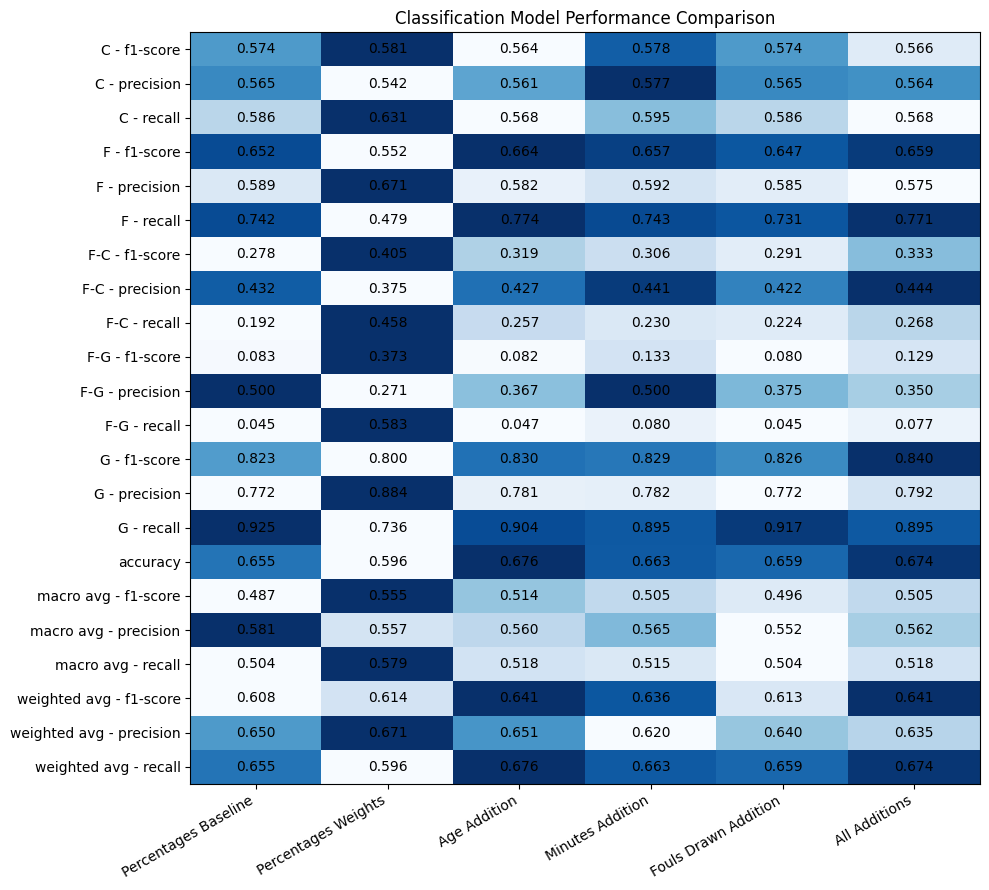

In [588]:
# Create heatmap
fig, ax = plt.subplots(figsize=(10, 9))

# Normalizing the scores within each row so that the coloring is
# distinguishable, need to do this because the differences in scores
# between models are relatively small so I don't want solid blue lines
normalized = comparison.sub(
    comparison.min(axis=1), axis=0
).div(
    comparison.max(axis=1) - comparison.min(axis=1), axis=0
)

# By applying the normalized scores in structuring of the heatmap I get
# the visual effect I want (will rewrite the shown values with actual ones
# though for interpretation purposes)
heatmap = ax.imshow(
    normalized,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto"
)

# Adding back original scores inside each cell
for row in range(len(comparison)):
    for col in range(len(comparison.columns)):
        value = comparison.iloc[row, col]

        ax.text(
            col, row,
            f"{value:.3f}",
            ha="center",
            va="center"
        )

# Labeling axes
ax.set_xticks(range(len(comparison.columns)))
ax.set_xticklabels(comparison.columns, rotation=30, ha="right")

ax.set_yticks(range(len(comparison.index)))
ax.set_yticklabels(comparison.index)

ax.set_title("Classification Model Performance Comparison")

plt.tight_layout()
plt.show()

### Metrics of Interest

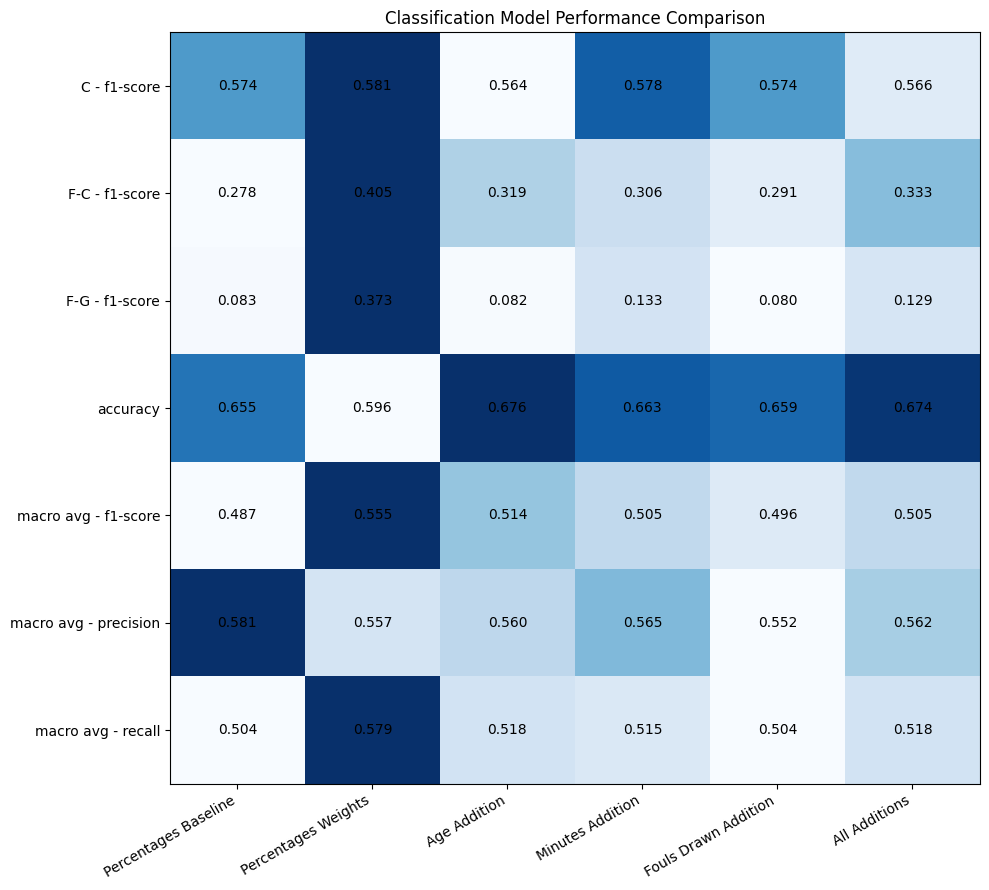

In [589]:
# Filtering to variables of particular interest
comparison_focused = comparison.iloc[[0,6,9,15,16,17,18]].copy()
comparison_focused.head()



# Create heatmap
fig, ax = plt.subplots(figsize=(10, 9))

# Normalizing the scores within each row so that the coloring is
# distinguishable, need to do this because the differences in scores
# between models are relatively small so I don't want solid blue lines
normalized = comparison_focused.sub(
    comparison_focused.min(axis=1), axis=0
).div(
    comparison_focused.max(axis=1) - comparison_focused.min(axis=1), axis=0
)

# By applying the normalized scores in structuring of the heatmap I get
# the visual effect I want (will rewrite the shown values with actual ones
# though for interpretation purposes)
heatmap = ax.imshow(
    normalized,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto"
)

# Adding back original scores inside each cell
for row in range(len(comparison_focused)):
    for col in range(len(comparison_focused.columns)):
        value = comparison_focused.iloc[row, col]

        ax.text(
            col, row,
            f"{value:.3f}",
            ha="center",
            va="center"
        )

# Labeling axes
ax.set_xticks(range(len(comparison_focused.columns)))
ax.set_xticklabels(comparison_focused.columns, rotation=30, ha="right")

ax.set_yticks(range(len(comparison_focused.index)))
ax.set_yticklabels(comparison_focused.index)

ax.set_title("Classification Model Performance Comparison")

plt.tight_layout()
plt.show()

Since accuracy is our most important metric, the age addition is best followed by the all additions model which shows somewhat better metrics in some areas.

# Final Model Comparison

## Attempts + All Additions

In [590]:
features_all = features_attempts + ['AGE', 'MIN_PER_GAME']

X = player_avg[features_all]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_all
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2A_PER12', 'FG3A_PER12', 'FTA_PER12', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'AGE', 'MIN_PER_GAME']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.694
Fold 2 - Accuracy: 0.694
Fold 3 - Accuracy: 0.665
Fold 4 - Accuracy: 0.697
Fold 5 - Accuracy: 0.649
Fold 6 - Accuracy: 0.678
Fold 7 - Accuracy: 0.611
Fold 8 - Accuracy: 0.668
Fold 9 - Accuracy: 0.611
Fold 10 - Accuracy: 0.683
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.575,0.637,0.599,24.700
F,0.588,0.763,0.662,61.900
F-C,0.547,0.267,0.347,22.500
F-G,0.375,0.072,0.119,23.000
G,0.793,0.900,0.843,76.200
accuracy,0.665,0.665,0.665,0.665
macro avg,0.576,0.528,0.514,208.300
weighted avg,0.636,0.665,0.626,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.568,0.625,0.587,26.500
F,0.569,0.771,0.664,62.500
F-C,0.500,0.290,0.360,22.000
F-G,0.417,0.073,0.128,23.000
G,0.794,0.895,0.831,77.000
accuracy,0.673,0.673,0.673,0.673
macro avg,0.572,0.530,0.511,208.000
weighted avg,0.655,0.673,0.642,208.000


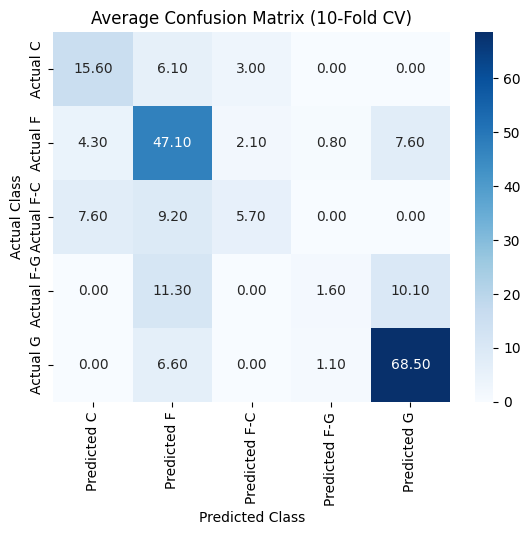

In [591]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_all_atmpt = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_all_atmpt.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

## Percentages + All Additions

In [592]:
features_all = features_percentages + ['AGE', 'MIN_PER_GAME', 'PFD_PER12']

X = player_avg[features_all]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_all
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2_PCT', 'FG3_PCT', 'FT_PCT', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'AGE', 'MIN_PER_GAME', 'PFD_PER12']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.675
Fold 2 - Accuracy: 0.684
Fold 3 - Accuracy: 0.641
Fold 4 - Accuracy: 0.712
Fold 5 - Accuracy: 0.644
Fold 6 - Accuracy: 0.683
Fold 7 - Accuracy: 0.62
Fold 8 - Accuracy: 0.683
Fold 9 - Accuracy: 0.615
Fold 10 - Accuracy: 0.673
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.587,0.592,0.586,24.700
F,0.591,0.763,0.664,61.900
F-C,0.472,0.282,0.347,22.500
F-G,0.389,0.072,0.120,23.000
G,0.792,0.903,0.843,76.200
accuracy,0.663,0.663,0.663,0.663
macro avg,0.566,0.522,0.512,208.300
weighted avg,0.632,0.663,0.626,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.564,0.568,0.566,26.500
F,0.575,0.771,0.659,62.500
F-C,0.444,0.268,0.333,22.000
F-G,0.350,0.077,0.129,23.000
G,0.792,0.895,0.840,77.000
accuracy,0.674,0.674,0.674,0.674
macro avg,0.562,0.518,0.505,208.000
weighted avg,0.635,0.674,0.641,208.000


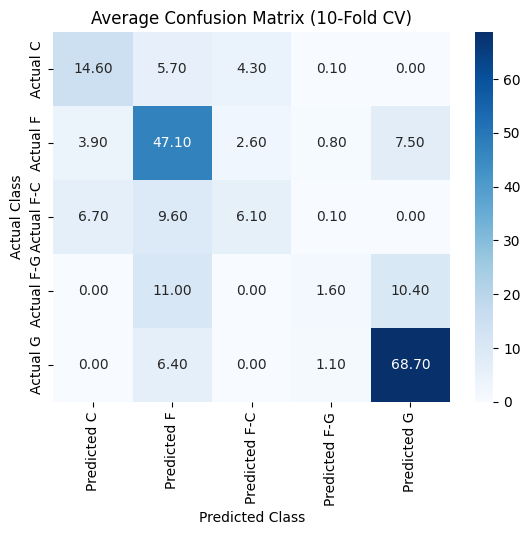

In [593]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_all_perc = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_all_perc.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

## Comparison

In [594]:
print("Attempts All Additions: Median Classification Report:")
display(median_report_all_atmpt.round(3))

print("Percentages All Additions: Median Classification Report:")
display(median_report_all_perc.round(3))

Attempts All Additions: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.568,0.625,0.587,26.500
F,0.569,0.771,0.664,62.500
F-C,0.500,0.290,0.360,22.000
F-G,0.417,0.073,0.128,23.000
G,0.794,0.895,0.831,77.000
accuracy,0.673,0.673,0.673,0.673
macro avg,0.572,0.530,0.511,208.000
weighted avg,0.655,0.673,0.642,208.000


Percentages All Additions: Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.564,0.568,0.566,26.500
F,0.575,0.771,0.659,62.500
F-C,0.444,0.268,0.333,22.000
F-G,0.350,0.077,0.129,23.000
G,0.792,0.895,0.840,77.000
accuracy,0.674,0.674,0.674,0.674
macro avg,0.562,0.518,0.505,208.000
weighted avg,0.635,0.674,0.641,208.000


Going with the attempts final model. Though percentages scores higher on accuracy by .01, the attempts model scores higher on most of the other metrics of interest (5/6): precision maacro avg, recall macro avg, f1 macro avg, C f1, and F-C f1.

# Final Model

In [595]:
features_all = features_attempts + ['AGE', 'MIN_PER_GAME']

X = player_avg[features_all]
y = pd.Categorical(player_avg[target])

# Pre-saving since I will be standardizing
numeric_features = features_all
print(f"Numeric features: {numeric_features}")

# Saving class labels for outputs
class_labels = np.unique(y)
print(f"Class labels: {class_labels}")

Numeric features: ['FG2A_PER12', 'FG3A_PER12', 'FTA_PER12', 'REB_PER12', 'BLK_PER12', 'PF_PER12', 'AST_PER12', 'TOV_PER12', 'STL_PER12', 'AGE', 'MIN_PER_GAME']
Class labels: ['C' 'F' 'F-C' 'F-G' 'G']


Fold 1 - Accuracy: 0.694
Fold 2 - Accuracy: 0.694
Fold 3 - Accuracy: 0.665
Fold 4 - Accuracy: 0.697
Fold 5 - Accuracy: 0.649
Fold 6 - Accuracy: 0.678
Fold 7 - Accuracy: 0.611
Fold 8 - Accuracy: 0.668
Fold 9 - Accuracy: 0.611
Fold 10 - Accuracy: 0.683
Mean Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.575,0.637,0.599,24.700
F,0.588,0.763,0.662,61.900
F-C,0.547,0.267,0.347,22.500
F-G,0.375,0.072,0.119,23.000
G,0.793,0.900,0.843,76.200
accuracy,0.665,0.665,0.665,0.665
macro avg,0.576,0.528,0.514,208.300
weighted avg,0.636,0.665,0.626,208.300


Median Classification Report:


,precision,recall,f1-score,support
Class,,,,
C,0.568,0.625,0.587,26.500
F,0.569,0.771,0.664,62.500
F-C,0.500,0.290,0.360,22.000
F-G,0.417,0.073,0.128,23.000
G,0.794,0.895,0.831,77.000
accuracy,0.673,0.673,0.673,0.673
macro avg,0.572,0.530,0.511,208.000
weighted avg,0.655,0.673,0.642,208.000


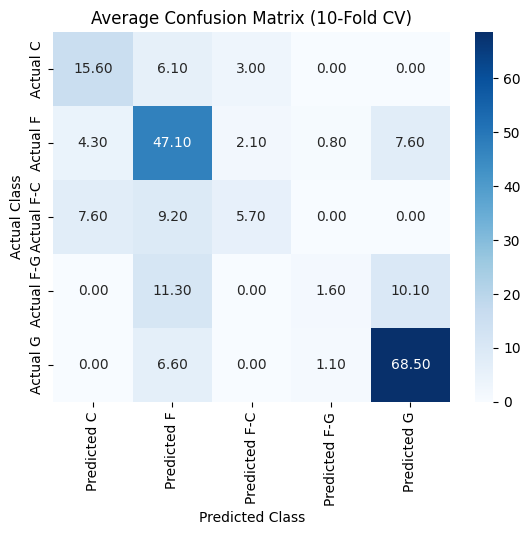

In [596]:
# Preparing to store fold results
fold_cms = []
fold_reports = []

for fold, (train_index, test_index) in enumerate(kf.split(X, y), 1):
  # Splitting data
  X_train = X.iloc[train_index]
  X_test = X.iloc[test_index]

  y_train = y[train_index]
  y_test = y[test_index]
  # Note: for splitting data for y didn't need .iloc because it was made
  # into a categorical array earlier

  # Standardizing numeric features using training data only
  scaler = StandardScaler()

  X_train_scaled = X_train.copy()
  X_test_scaled = X_test.copy()

  # fit_transform() fits the scaler and transforms data in one step
  X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])

  # transform() standardizes data using learned statistics from previous fitting
  X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

  # Fit multinomial logistic regression
  model = LogisticRegression()
  model.fit(X_train_scaled, y_train)

  # Predict position
  y_pred = model.predict(X_test_scaled)

  # Save classification report
  report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True, # will allow me to turn into DataFrame to get mean and
        # median performance metrics
        zero_division=0
    )

  # Turning classification report into DataFrame and appending to tracker
  fold_reports.append(pd.DataFrame(report).T)
  #.T transposes DataFrame making rows into columns this will make each class
  # have its own row so I can calculate metrics accordingly

  # Saving the confusion matrix
  cm = confusion_matrix(y_test, y_pred, labels=class_labels)
  fold_cms.append(cm)

  print(f"Fold {fold} - Accuracy: {round(accuracy_score(y_test, y_pred), 3)}")

all_reports = pd.concat(
    fold_reports,
    keys=range(1,11), # corresponds to what fold values are from
    names=['Fold','Class'] # creates index for keys as Fold and then second as class
    # for the classification category (position, etc.)
)

# Mean classification report
mean_report = all_reports.groupby("Class").mean()

print("Mean Classification Report:")
display(mean_report.round(3))

# Median classification report
median_report_all_atmpt = all_reports.groupby("Class").median()

print("Median Classification Report:")
display(median_report_all_atmpt.round(3))

cm_df = pd.DataFrame(
    np.mean(fold_cms, axis=0),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

sns.heatmap(cm_df,
            annot=True,
            fmt=".2f",
            cmap="Blues")
plt.title(f"Average Confusion Matrix (10-Fold CV)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

Log-Odds Summary Table
     Intercept  FG2A_PER12  FG3A_PER12  FTA_PER12  REB_PER12  BLK_PER12  \
C      -1.9128      0.0662     -0.7092    -0.0879     1.4537     1.0059   
F       1.7661      0.0035      0.0139     0.0010     0.5647    -0.1622   
F-C    -0.5776     -0.0450      0.1563    -0.0614     1.5910     0.6869   
F-G     0.6842     -0.1148      0.1254     0.0896    -0.9699    -0.5527   
G       0.0402      0.0900      0.4136     0.0587    -2.6395    -0.9779   

     PF_PER12  AST_PER12  TOV_PER12  STL_PER12     AGE  MIN_PER_GAME  
C      0.7016    -0.4978     0.1118    -0.9084  0.3023        0.2640  
F     -0.2638    -0.7634     0.1000     0.1807 -0.1045        0.0578  
F-C    0.5078    -0.3651     0.0600    -0.5545  0.4060        0.2811  
F-G   -0.4042     0.1073    -0.1572     0.5990 -0.1538       -0.0377  
G     -0.5414     1.5189    -0.1147     0.6832 -0.4500       -0.5652  

Odds Ratio (Exponentiated) Summary Table
     Intercept  FG2A_PER12  FG3A_PER12  FTA_PER12  REB_PER

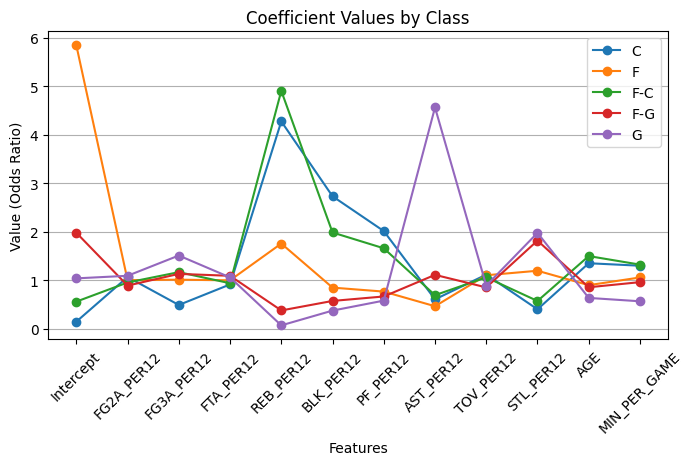

In [597]:
# Extracting intercepts and coefficients to evaluate
# Extracting intercepts
intercept_df = pd.DataFrame(
    model.intercept_,
    index=class_labels,
    columns=["Intercept"]
)

# Extracting coefficients
coef_df = pd.DataFrame(
    model.coef_,
    index=class_labels,
    columns=features_all
)

# Combining both into a clearly labeled table
full_summary = pd.concat([intercept_df, coef_df], axis=1)

print("Log-Odds Summary Table")
print(full_summary.round(4))

print("\nOdds Ratio (Exponentiated) Summary Table")
print(np.exp(full_summary).round(4))

# Taking a closer look at OR and comparing visually
# Have to transpose using .T so that each class is its own column during plotting
summary_flipped = np.exp(full_summary).T

# Initializing the plot
summary_flipped.plot(kind="line", marker="o", figsize=(8, 4), rot=45, xticks=range(len(summary_flipped)))

# Adding the labels
plt.title("Coefficient Values by Class")
plt.ylabel("Value (Odds Ratio)")
plt.xlabel("Features")
plt.grid(True, axis="y")

plt.show()